# Milestone 2 – Evaluation

This notebook evaluates all generated images from the Milestone 2 experiments using CLIP. It calculates image–text similarity scores, consolidates experiment logs, generates performance visualizations, and prepares representative samples for submission.

The evaluation supports both Stable Diffusion 1.5 (`sd15`) and Stable Diffusion 2.1 (`sd21`). Each model's results can be evaluated independently as images become available, with a final evaluation performed once all experiments are complete.

## Inputs

- `data/prompt_set_m2.csv`: Prompt manifest containing `image_id`, `category`, `caption`, and `file_path`.
- `results/milestone2/run_log_<RUN_TAG>.csv`: Experiment execution logs.
- `results/milestone2/config_<RUN_TAG>.json`: Configuration and experiment settings.
- `results/milestone2/images/<RUN_TAG>/*.png`: Generated images for each experiment.

## Outputs

All evaluation outputs are saved under `results/milestone2/`.

- `clip_scores_<RUN_TAG>.csv`: Per-image CLIP scores, containing `filename` and `clip_score`. These files are maintained separately for each run to avoid modifying experiment logs during generation.
- `clip_scorer.json`: Records the CLIP model, revision, and scoring formula to ensure consistency across evaluation sessions.
- `run_log.csv`: Consolidated experiment log containing all available runs and their corresponding CLIP scores.
- `summary_by_setting.csv`: Aggregated results by model and experimental setting, including mean CLIP score, change relative to the baseline, generation time, and memory usage.
- `plot_clip_vs_guidance.png`: Visualization of CLIP scores across guidance scale settings.
- `plot_quality_time_vs_steps.png`: Comparison of prompt alignment and generation time across inference steps.
- `submission/`: Contains representative image strips for guidance scale and scheduler comparisons, along with the individual images included in each strip.

## CLIP Scoring Methodology

The evaluation uses the following formula:

\[
\text{CLIP Score} = 100 \times \max(\cos(I,T),0)
\]

Where:
- \(I\) represents the image embedding.
- \(T\) represents the corresponding caption embedding.
- \(\cos(I,T)\) represents cosine similarity between the two embeddings.

Each generated image is evaluated at a resolution of 512 × 512 pixels against the COCO caption used during generation.

CLIP measures semantic alignment between the generated image and its corresponding text prompt. It does not directly measure visual realism or image quality. Realism and distributional similarity are evaluated separately using FID in the subsequent evaluation stage.

## CLIP Model Selection

The evaluation uses `openai/clip-vit-base-patch32` as the common scoring model for both Stable Diffusion versions.

Stable Diffusion 1.5 and Stable Diffusion 2.1 use different text-conditioning architectures. Using either model's native text encoder for evaluation could introduce a scoring bias. ViT-B/32 provides a consistent, independent scoring model, ensuring that both image-generation models are assessed using the same evaluation criteria.

The `CLIP_MODEL` configuration parameter allows the scoring model to be changed. Any change requires setting `RESCORE = True` to regenerate scores using the selected model.

The scorer configuration is verified whenever evaluation resumes, preventing scores from different models or revisions from being unintentionally combined.

## Execution and Resume Strategy

- **GPU runtime:** Recommended for faster evaluation, although CPU execution is also supported.
- **Partial evaluation:** Set `ALLOW_PARTIAL = True` to evaluate available images while experiments are still running.
- **Final evaluation:** Set `ALLOW_PARTIAL = False` to enforce completeness checks and identify missing log entries or generated images.
- **Resume support:** Previously calculated scores are reused when the scorer configuration remains unchanged. Only images requiring evaluation are processed.
- **Package consistency:** The notebook uses the same dependency versions as the image-generation environment. If the initial setup cell modifies installed packages, restart the runtime and execute the notebook again.

## 1. Setup and Configuration

The notebook initializes the required libraries, dependencies, and evaluation environment. Experiment configurations, including baseline settings, guidance scales, inference steps, and scheduler choices, are loaded directly from the corresponding run configuration file.

This ensures that evaluation and reporting remain consistent with the actual experimental settings.

In [1]:
from pathlib import Path
from importlib.metadata import version


try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path("/content/drive/MyDrive/IE7615_Project2")
except ImportError:
    ROOT = Path("./IE7615_Project2")

REQ = ROOT / "requirements.txt"
if REQ.exists():
    PINS = " ".join(l for l in REQ.read_text().split() if not l.startswith(("torch==", "torchvision==")))
    !pip -q install {PINS} jedi
    !pip -q uninstall -y torchvision
print(REQ.read_text())

torch_pin = next(l for l in REQ.read_text().split() if l.startswith("torch=="))
TV_VERSION = f"0.{int(torch_pin.split('==')[1].split('.')[1]) + 15}.0"
!pip -q install "torchvision=={TV_VERSION}"
!pip check

Mounted at /content/drive
torch==2.11.0
diffusers==0.42.1
transformers==5.22.0
accelerate==1.15.0

No broken requirements found.


In [2]:
import subprocess, sys

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return r.returncode == 0, (r.stdout + r.stderr).strip().splitlines()[-1:]

TEST = f'{sys.executable} -c "from transformers import CLIPImageProcessor; from diffusers import StableDiffusionPipeline"'
ok, tail = sh(TEST)
print("imports work:", ok, tail)
fixed = False

if not ok:
    sh(f"{sys.executable} -m pip -q uninstall -y torchvision")
    ok, tail = sh(TEST); fixed = True
    print("after removing torchvision:", ok, tail)

if not ok:
    _, v = sh(f'{sys.executable} -c "import torch; print(torch.__version__)"')
    minor = int(v[0].split(".")[1])
    sh(f"{sys.executable} -m pip -q install --no-deps --force-reinstall torchvision==0.{minor + 15}.0")
    ok, tail = sh(TEST)
    print(f"after installing torchvision 0.{minor + 15}.0:", ok, tail)

assert ok, "Still failing: paste the three lines printed above"
if fixed:
    print("FIXED: Runtime > Restart session, then run all again (this cell should then print 'imports work: True')")

imports work: True []


In [3]:
import csv, json, os, re, shutil, textwrap
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [4]:
#config
RUN_VERSION   = "v1"
MODEL_TAGS    = ["sd15", "sd21"]
RUN_TAGS      = {t: f"m2_{t}_{RUN_VERSION}" for t in MODEL_TAGS}
CAPTION_COL   = "caption"
RESCORE       = False                   # True: recompute every CLIP score
ALLOW_PARTIAL = False                   # True only while a sweep is still running

#scorer
CLIP_MODEL = "openai/clip-vit-base-patch32"
CLIP_BATCH = 16
FORMULA    = "100 * max(cos(image_emb, text_emb), 0)"

#submission samples: one strip per sweep, both from SAMPLE_MODELS
SAMPLE_MODELS          = ["sd15"]
STRIP_PROMPT_GUIDANCE  = 27972          # colour_binding: one prompt across guidance values
STRIP_PROMPT_SCHEDULER = 1761           # counting: one prompt across schedulers

#run_log columns
LOG_COLUMNS = ["run_tag", "model_tag", "checkpoint", "revision", "image_id", "category", "emb_row",
               "scheduler", "steps", "guidance", "seed", "height", "width", "dtype",
               "filename", "gen_time_s", "peak_gpu_mem_gb", "gpu_name", "timestamp", "clip_score"]

DATA        = ROOT / "data"
M2_RESULTS  = ROOT / "results" / "milestone2"
SUBMIT_DIR  = M2_RESULTS / "submission"
SUBMIT_DIR.mkdir(parents=True, exist_ok=True)

PROMPT_FILE = DATA / "prompt_set_m2.csv"
RUN_LOG     = M2_RESULTS / "run_log.csv"
SCORER_FILE = M2_RESULTS / "clip_scorer.json"
RUN_LOGS    = {t: M2_RESULTS / f"run_log_{RUN_TAGS[t]}.csv" for t in MODEL_TAGS}
CFG_FILES   = {t: M2_RESULTS / f"config_{RUN_TAGS[t]}.json" for t in MODEL_TAGS}
IMG_DIRS    = {t: M2_RESULTS / "images" / RUN_TAGS[t] for t in MODEL_TAGS}
SCORE_FILES = {t: M2_RESULTS / f"clip_scores_{RUN_TAGS[t]}.csv" for t in MODEL_TAGS}
print("run tags:", RUN_TAGS)

run tags: {'sd15': 'm2_sd15_v1', 'sd21': 'm2_sd21_v1'}


In [5]:
GENERATE_MODELS = ["sd21"]
import time, torch, diffusers, transformers
from diffusers import (StableDiffusionPipeline, PNDMScheduler, DDIMScheduler,
                       EulerDiscreteScheduler, DPMSolverMultistepScheduler)

CHECKPOINTS = {"sd15": "stable-diffusion-v1-5/stable-diffusion-v1-5",
               "sd21": "sd2-community/stable-diffusion-2-1-base"}
SCHEDULERS = {"pndm": PNDMScheduler, "ddim": DDIMScheduler,
              "euler": EulerDiscreteScheduler, "dpmpp_2m": DPMSolverMultistepScheduler}


_sd15_cfg = CFG_FILES["sd15"]
if _sd15_cfg.exists():
    _c = json.loads(_sd15_cfg.read_text())
    G = {k: _c[k] for k in ["baseline", "guidance_values", "step_values", "scheduler_names",
                            "seed", "height", "width", "dtype"]}
else:
    G = dict(baseline={"scheduler": "ddim", "steps": 30, "guidance": 7.5},
             guidance_values=[1.0, 3.0, 5.0, 7.5, 10.0, 15.0], step_values=[10, 20, 30, 50],
             scheduler_names=["pndm", "ddim", "euler", "dpmpp_2m"],
             seed=42, height=512, width=512, dtype="float16")

def fname(run_tag, image_id, scheduler, steps, guidance, seed):
    return f"{run_tag}__id{image_id}__{scheduler}__s{steps:02d}__g{guidance:04.1f}__seed{seed}.png"

def generate_model(tag):
    dev = "cuda"
    run_tag, img_dir = RUN_TAGS[tag], IMG_DIRS[tag]
    img_dir.mkdir(parents=True, exist_ok=True)
    pr = pd.read_csv(PROMPT_FILE)

    # saved embeddings
    emb = torch.load(ROOT / "embeddings" / f"text_embeddings_{tag}_{CAPTION_COL}.pt", map_location="cpu")
    assert emb["checkpoint"] == CHECKPOINTS[tag], f"embeddings made with {emb['checkpoint']}"
    for r in pr.itertuples():
        assert emb["image_ids"][r.emb_row] == r.image_id, f"emb_row mismatch for {r.image_id}"
    ckpt, rev = emb["checkpoint"], emb["revision"]
    cond_cpu = {int(r): emb["hidden"][int(r)].unsqueeze(0).clone() for r in pr["emb_row"]}
    uncond_cpu = emb["uncond_hidden"].clone()
    del emb

    pipe = StableDiffusionPipeline.from_pretrained(
        ckpt, revision=rev, dtype=getattr(torch, G["dtype"]),
        safety_checker=None, requires_safety_checker=False).to(dev)
    pipe.set_progress_bar_config(disable=True)
    base_cfg = dict(pipe.scheduler.config)
    cond = {k: v.to(dev, pipe.unet.dtype) for k, v in cond_cpu.items()}
    uncond = uncond_cpu.to(dev, pipe.unet.dtype)

    def set_sched(n):
        pipe.scheduler = SCHEDULERS[n].from_config(base_cfg)

    # run config
    run_cfg = {"run_tag": run_tag, "model_tag": tag, "checkpoint": ckpt, "revision": rev,
               "seed": G["seed"], "height": G["height"], "width": G["width"], "dtype": G["dtype"],
               "prompt_image_ids": pr["image_id"].tolist(),
               "torch": torch.__version__, "diffusers": diffusers.__version__,
               "transformers": transformers.__version__,
               "baseline": G["baseline"], "guidance_values": G["guidance_values"],
               "step_values": G["step_values"], "scheduler_names": G["scheduler_names"]}
    if CFG_FILES[tag].exists():
        old = json.loads(CFG_FILES[tag].read_text())
        diff = {k: (old.get(k), run_cfg[k]) for k in
                ["checkpoint", "revision", "seed", "height", "width", "dtype", "prompt_image_ids"]
                if old.get(k) != run_cfg[k]}
        assert not diff, f"config changed since {run_tag} started: {diff}. Use a new RUN_VERSION."
    else:
        CFG_FILES[tag].write_text(json.dumps(run_cfg, indent=2))

    # job list: baseline + guidance sweep + steps x scheduler sweep, duplicates removed
    b = G["baseline"]
    settings = {(b["scheduler"], b["steps"], b["guidance"])}
    settings |= {(b["scheduler"], b["steps"], g) for g in G["guidance_values"]}
    settings |= {(sc, st, b["guidance"]) for sc in G["scheduler_names"] for st in G["step_values"]}
    settings = sorted(settings, key=lambda s: (G["scheduler_names"].index(s[0]), s[1], s[2]))
    jobs = [dict(scheduler=sc, steps=st, guidance=g, image_id=int(r.image_id), category=r.category,
                 emb_row=int(r.emb_row), seed=G["seed"],
                 filename=fname(run_tag, int(r.image_id), sc, st, g, G["seed"]))
            for (sc, st, g) in settings for r in pr.itertuples()]

    logged = set(pd.read_csv(RUN_LOGS[tag])["filename"]) if RUN_LOGS[tag].exists() else set()
    todo = [j for j in jobs if not ((img_dir / j["filename"]).exists() and j["filename"] in logged)]
    print(f"{tag}: {len(jobs) - len(todo)} done, {len(todo)} to generate")


    set_sched("ddim")
    pipe(prompt_embeds=next(iter(cond.values())), negative_prompt_embeds=uncond, num_inference_steps=2,
         guidance_scale=7.5, height=G["height"], width=G["width"],
         generator=torch.Generator(dev).manual_seed(0))
    gpu = torch.cuda.get_device_name(0)

    for j in tqdm(todo, desc=f"generate {tag}"):
        set_sched(j["scheduler"])
        gen = torch.Generator(dev).manual_seed(j["seed"])
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter()
        with torch.no_grad():
            img = pipe(prompt_embeds=cond[j["emb_row"]], negative_prompt_embeds=uncond,
                       num_inference_steps=j["steps"], guidance_scale=j["guidance"],
                       height=G["height"], width=G["width"], generator=gen).images[0]
        torch.cuda.synchronize()
        dt, peak = time.perf_counter() - t0, torch.cuda.max_memory_allocated() / 1e9
        tmp = img_dir / (j["filename"] + ".tmp")
        img.save(tmp, format="PNG"); os.replace(tmp, img_dir / j["filename"])
        new = not RUN_LOGS[tag].exists()
        with open(RUN_LOGS[tag], "a", newline="") as f:
            w = csv.DictWriter(f, fieldnames=LOG_COLUMNS)
            if new: w.writeheader()
            w.writerow({"run_tag": run_tag, "model_tag": tag, "checkpoint": ckpt, "revision": rev,
                        "image_id": j["image_id"], "category": j["category"], "emb_row": j["emb_row"],
                        "scheduler": j["scheduler"], "steps": j["steps"], "guidance": j["guidance"],
                        "seed": j["seed"], "height": G["height"], "width": G["width"], "dtype": G["dtype"],
                        "filename": j["filename"], "gen_time_s": round(dt, 3),
                        "peak_gpu_mem_gb": round(peak, 3), "gpu_name": gpu,
                        "timestamp": datetime.now().isoformat(timespec="seconds"), "clip_score": ""})
    del pipe; torch.cuda.empty_cache()

if GENERATE_MODELS:
    assert torch.cuda.is_available(), "Switch the runtime to a GPU (T4) to generate"
    from tqdm.auto import tqdm
    for t in GENERATE_MODELS:
        generate_model(t)

model_index.json:   0%|          | 0.00/543 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

sd21: 0 done, 210 to generate


generate sd21:   0%|          | 0/210 [00:00<?, ?it/s]

## 2. Load Prompt Manifest, Configurations, and Run Logs

This section loads the prompt manifest, experiment configurations, and execution logs for both Stable Diffusion models.

Before proceeding with CLIP scoring, it performs a series of validation checks to ensure the experimental data is complete and consistent:

- **Log structure validation:** Verifies that each run log contains the expected columns defined in `LOG_COLUMNS`.
- **Prompt consistency:** Confirms that both models were evaluated using the same set of prompts.
- **Experiment consistency:** Checks that both models share the same experimental settings to ensure a fair comparison.
- **Image completeness:** Verifies that every planned image has exactly one corresponding log entry and that its generated PNG file exists.
- **GPU consistency:** Checks that both models were executed using the same GPU type, based on the `gpu_name` field in the run logs. This is necessary to ensure that generation-time comparisons are meaningful.

If a model's run log is not yet available, it is skipped with an informational message rather than causing the evaluation to

In [6]:
prompts = pd.read_csv(PROMPT_FILE)
cap_of = prompts.set_index("image_id")[CAPTION_COL].to_dict()
for i in (STRIP_PROMPT_GUIDANCE, STRIP_PROMPT_SCHEDULER):
    assert i in cap_of, f"strip prompt {i} is not in the prompt set"

AVAILABLE = [t for t in MODEL_TAGS if RUN_LOGS[t].exists() and CFG_FILES[t].exists()]
print("models with a run log:", AVAILABLE, "| not run yet:", [t for t in MODEL_TAGS if t not in AVAILABLE])
assert AVAILABLE, "no run_log_<RUN_TAG>.csv found; check RUN_VERSION and the Drive folder"

cfgs = {t: json.loads(CFG_FILES[t].read_text()) for t in AVAILABLE}
SHARED = ["prompt_image_ids", "baseline", "guidance_values", "step_values", "scheduler_names",
          "seed", "height", "width"]
ref = cfgs[AVAILABLE[0]]
for t in AVAILABLE[1:]:
    diff = {k: (ref[k], cfgs[t][k]) for k in SHARED if ref[k] != cfgs[t][k]}
    assert not diff, f"{t} was run with different settings than {AVAILABLE[0]}: {diff}"
assert ref["prompt_image_ids"] == prompts["image_id"].tolist(), "run prompts differ from prompt_set_m2.csv"

BASELINE        = ref["baseline"]
GUIDANCE_VALUES = ref["guidance_values"]
STEP_VALUES     = ref["step_values"]
SCHEDULER_NAMES = ref["scheduler_names"]

expected = {(BASELINE["scheduler"], BASELINE["steps"], g) for g in GUIDANCE_VALUES}
expected |= {(sc, st, BASELINE["guidance"]) for sc in SCHEDULER_NAMES for st in STEP_VALUES}
n_expected = len(expected) * len(prompts)

logs = {}
for t in AVAILABLE:
    header = next(csv.reader(open(RUN_LOGS[t])))
    assert header == LOG_COLUMNS, f"{RUN_LOGS[t].name} header differs from LOG_COLUMNS:\n{header}"
    lg = pd.read_csv(RUN_LOGS[t])
    n_dup = int(lg.duplicated("filename").sum())
    lg = lg.drop_duplicates("filename", keep="last").reset_index(drop=True)
    missing_png = [f for f in lg["filename"] if not (IMG_DIRS[t] / f).exists()]
    got = set(zip(lg["scheduler"], lg["steps"], lg["guidance"].astype(float)))
    print(f"{t}: {len(lg)} rows (full sweep = {n_expected}) | duplicate rows dropped {n_dup} | "
          f"missing PNGs {len(missing_png)} | settings missing {len(expected - got)} | "
          f"GPU {sorted(lg['gpu_name'].unique())}")
    if not ALLOW_PARTIAL:
        assert len(lg) == n_expected and got == expected and not missing_png, \
            f"{t} is incomplete: finish the sweep in 03 (or set ALLOW_PARTIAL = True for a test run)"
    else:
        assert not missing_png, missing_png[:3]
    logs[t] = lg

gpus = {t: tuple(sorted(logs[t]["gpu_name"].unique())) for t in AVAILABLE}
if len(set(gpus.values())) > 1:
    print("WARNING: the models ran on different GPU types", gpus, "- compare times within a model, not between models")

models with a run log: ['sd15', 'sd21'] | not run yet: []
sd15: 210 rows (full sweep = 210) | duplicate rows dropped 0 | missing PNGs 0 | settings missing 0 | GPU ['Tesla T4']
sd21: 210 rows (full sweep = 210) | duplicate rows dropped 0 | missing PNGs 0 | settings missing 0 | GPU ['Tesla T4']


## 3. CLIP Scorer

This section initializes `openai/clip-vit-base-patch32` and defines `clip_scores(images, captions)` to calculate image–caption similarity scores.

- **Model consistency:** Saves the checkpoint revision in `clip_scorer.json` and reuses it across sessions.
- **Preprocessing:** Processes 512 × 512 images using CLIP's standard 224 × 224 resizing and center cropping.
- **Caption processing:** Applies a 77-token limit.
- **Scoring:** Computes cosine similarity in float32, clips negative scores to zero, and scales results by 100.

### Validation Using Real COCO Images

Before scoring generated images, two checks are performed using the 10 original COCO images:

1. Each image should score higher with its matching caption than with an unrelated caption.
2. Individual and batch scoring should produce consistent results.

The mean CLIP score of the real images is retained as a reference benchmark for the plots.

In [7]:
import torch
import torch.nn.functional as F
import transformers
from huggingface_hub import HfApi
from transformers import CLIPModel, CLIPProcessor
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
saved_scorer = json.loads(SCORER_FILE.read_text()) if SCORER_FILE.exists() else None
if saved_scorer and not RESCORE:
    assert (saved_scorer["clip_model"], saved_scorer["formula"]) == (CLIP_MODEL, FORMULA), \
        f"existing scores were made with {saved_scorer['clip_model']}: set RESCORE = True to rescore everything"
    CLIP_REVISION = saved_scorer["revision"]
else:
    CLIP_REVISION = HfApi().model_info(CLIP_MODEL).sha

processor = CLIPProcessor.from_pretrained(CLIP_MODEL, revision=CLIP_REVISION)
clip = CLIPModel.from_pretrained(CLIP_MODEL, revision=CLIP_REVISION).to(DEVICE).eval()
print("scorer:", CLIP_MODEL, "| revision:", CLIP_REVISION[:10], "| device:", DEVICE, "| transformers", transformers.__version__)

@torch.no_grad()
def clip_scores(images, captions):
    inp = processor(text=list(captions), images=list(images), return_tensors="pt",
                    padding=True, truncation=True, max_length=77).to(DEVICE)
    out = clip(**inp)
    img = F.normalize(out.image_embeds.float(), dim=-1)
    txt = F.normalize(out.text_embeds.float(), dim=-1)
    return (100 * (img * txt).sum(-1)).clamp(min=0).cpu().tolist()

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

scorer: openai/clip-vit-base-patch32 | revision: 3d74acf9a2 | device: cuda | transformers 5.22.0


In [8]:
def load_rgb(path):
    with Image.open(path) as im:
        return im.convert("RGB")

real  = [load_rgb(DATA / p) for p in prompts["file_path"]]
caps  = prompts[CAPTION_COL].tolist()
n     = len(caps)
own   = np.array(clip_scores(real, caps))
other = np.array(clip_scores(real, [caps[(i + 1) % n] for i in range(n)]))
single = clip_scores(real[:1], caps[:1])[0]

check = pd.DataFrame({"image_id": prompts["image_id"], "category": prompts["category"],
                      "own_caption": own.round(2), "other_caption": other.round(2)})
print(check.to_string(index=False))
print(f"own > other for {(own > other).sum()}/{n} images | mean own {own.mean():.2f}, mean other {other.mean():.2f}")
print(f"single vs batch for the first pair: {single:.3f} vs {own[0]:.3f}")
assert (own > other).mean() >= 0.8, "scorer does not separate matched from mismatched captions: check the model/processor"
assert abs(single - own[0]) < 0.05, "score depends on batch composition: check padding"

REAL_MEAN = float(own.mean())
REAL_BY_ID = dict(zip(prompts["image_id"], own))

if RESCORE or not saved_scorer:
    SCORER_FILE.write_text(json.dumps({"clip_model": CLIP_MODEL, "revision": CLIP_REVISION, "formula": FORMULA,
                                       "real_image_mean": round(REAL_MEAN, 4),
                                       "created": datetime.now().isoformat(timespec="seconds")}, indent=2))
print("scorer settings in", SCORER_FILE.name)

 image_id         category  own_caption  other_caption
     1761         counting        29.80          15.67
    97924    people_action        32.26          11.74
    25181 spatial_relation        25.38          14.03
     3661     simple_scene        29.51          19.36
     5600      two_objects        31.08          11.59
    27972   colour_binding        33.62          16.74
   214200     visible_text        30.73          20.17
    12670            crowd        27.45          18.07
    88269     food_closeup        36.71          17.18
     7574 cluttered_indoor        29.68          11.41
own > other for 10/10 images | mean own 30.62, mean other 15.59
single vs batch for the first pair: 29.799 vs 29.799
scorer settings in clip_scorer.json


## 4. Score the Generated Images

Generated images from each model are evaluated independently, with scores saved to the corresponding `clip_scores_<RUN_TAG>.csv` file after every batch.

Previously scored images are automatically skipped, allowing evaluation to resume after interruptions without repeating completed work. Setting `RESCORE = True` forces all scores to be recalculated.

Results are written through a temporary file and renamed upon completion to prevent incomplete or corrupted output files.

In [9]:
def write_scores(path, scores):
    tmp = path.with_suffix(".tmp")
    pd.DataFrame({"filename": list(scores), "clip_score": list(scores.values())}).to_csv(tmp, index=False)
    os.replace(tmp, path)

for t in AVAILABLE:
    path = SCORE_FILES[t]
    scores = {} if (RESCORE or not path.exists()) else dict(pd.read_csv(path)[["filename", "clip_score"]].values)
    todo = [r for r in logs[t].itertuples() if r.filename not in scores]
    print(f"{t}: {len(logs[t]) - len(todo)} already scored, {len(todo)} to score")
    for k in tqdm(range(0, len(todo), CLIP_BATCH), desc=t):
        batch = todo[k:k + CLIP_BATCH]
        imgs = [load_rgb(IMG_DIRS[t] / r.filename) for r in batch]
        vals = clip_scores(imgs, [cap_of[r.image_id] for r in batch])
        scores.update({r.filename: round(v, 4) for r, v in zip(batch, vals)})
        write_scores(path, scores)
    print(f"{t}: {len(scores)} scores in {path.name}")

sd15: 210 already scored, 0 to score


sd15: 0it [00:00, ?it/s]

sd15: 210 scores in clip_scores_m2_sd15_v1.csv
sd21: 0 already scored, 210 to score


sd21:   0%|          | 0/14 [00:00<?, ?it/s]

sd21: 210 scores in clip_scores_m2_sd21_v1.csv


## 5. Complete `run_log.csv`

This section consolidates all `run_log_*.csv` files into a single `run_log.csv`, retaining the latest entry for each filename and preserving the predefined `LOG_COLUMNS` order.

CLIP scores are merged from the corresponding `clip_scores_*.csv` files. Validation checks ensure that:

- Experiment settings encoded in each filename match the corresponding log entry.
- Every image belonging to the current run tags has an associated CLIP score.

This section should be rerun whenever the experiment logs are regenerated to ensure the consolidated log includes the latest CLIP scores.

In [10]:
parts  = [pd.read_csv(f) for f in sorted(M2_RESULTS.glob("run_log_*.csv"))]
merged = pd.concat(parts).drop_duplicates("filename", keep="last")[LOG_COLUMNS].reset_index(drop=True)
sc_all = pd.concat([pd.read_csv(f) for f in sorted(M2_RESULTS.glob("clip_scores_*.csv"))])
sc_all = sc_all.drop_duplicates("filename", keep="last").set_index("filename")["clip_score"]
merged["clip_score"] = merged["filename"].map(sc_all)

PAT = re.compile(r"__id(\d+)__([a-z0-9_]+?)__s(\d+)__g([\d.]+)__seed(\d+)\.png$")
bad = []
for r in merged.itertuples():
    m = PAT.search(r.filename)
    if not m or (int(m[1]), m[2], int(m[3]), float(m[4]), int(m[5])) != \
                (r.image_id, r.scheduler, r.steps, float(r.guidance), r.seed):
        bad.append(r.filename)
cur = merged["run_tag"].isin(RUN_TAGS.values())
unscored = merged[cur & merged["clip_score"].isna()]
dups = merged[cur].duplicated(["run_tag", "image_id", "scheduler", "steps", "guidance"]).sum()
print(f"rows {len(merged)} | filename/row mismatches {len(bad)} | duplicate settings {dups} | "
      f"rows without a score {len(unscored)} | per run: {merged.groupby('run_tag').size().to_dict()}")
assert not bad and not dups, (bad[:3], dups)
assert ALLOW_PARTIAL or unscored.empty, "some rows have no CLIP score: run section 4 again"

merged.to_csv(RUN_LOG, index=False)
print("saved", RUN_LOG.name)

rows 420 | filename/row mismatches 0 | duplicate settings 0 | rows without a score 0 | per run: {'m2_sd15_v1': 210, 'm2_sd21_v1': 210}
saved run_log.csv


## 6. Summary Table

This section generates a summary for each model and experimental setting across the 10 prompts.

The table reports mean CLIP score, paired change against the baseline (`clip_delta_vs_baseline`), standard error, generation time, and peak memory usage.

CLIP differences are calculated using the same prompts and seeds to account for prompt difficulty. With only 10 prompts and one seed, differences smaller than approximately two standard errors should be interpreted cautiously.

Generation time includes the full pipeline call, including VAE decoding, while peak memory includes model weights.

In [11]:
df = merged[merged["run_tag"].isin(RUN_TAGS.values())].copy()
df["clip_score"] = pd.to_numeric(df["clip_score"])
df["guidance"] = df["guidance"].astype(float)
MODELS = [t for t in MODEL_TAGS if t in set(df["model_tag"])]
b = BASELINE

base = df[(df.scheduler == b["scheduler"]) & (df.steps == b["steps"]) & (df.guidance == b["guidance"])]
base = base[["model_tag", "image_id", "clip_score"]].rename(columns={"clip_score": "clip_base"})
paired = df.merge(base, on=["model_tag", "image_id"])
paired["delta"] = paired["clip_score"] - paired["clip_base"]

summary = (paired.groupby(["model_tag", "scheduler", "steps", "guidance"])
           .agg(n=("image_id", "size"), clip_mean=("clip_score", "mean"), clip_sd=("clip_score", "std"),
                clip_delta_vs_baseline=("delta", "mean"),
                clip_delta_se=("delta", lambda x: x.std() / np.sqrt(len(x))),
                time_mean_s=("gen_time_s", "mean"), peak_gpu_mem_gb=("peak_gpu_mem_gb", "max"))
           .round(3).reset_index())
summary.to_csv(M2_RESULTS / "summary_by_setting.csv", index=False)
print("saved summary_by_setting.csv\n")

print("guidance sweep (scheduler and steps at baseline):")
gs = summary[(summary.scheduler == b["scheduler"]) & (summary.steps == b["steps"])]
print(gs.drop(columns=["scheduler", "steps", "clip_sd"]).to_string(index=False))
print("\nsteps x scheduler (guidance at baseline):")
ss = summary[summary.guidance == b["guidance"]]
print(ss.drop(columns=["guidance", "clip_sd"]).to_string(index=False))

saved summary_by_setting.csv

guidance sweep (scheduler and steps at baseline):
model_tag  guidance  n  clip_mean  clip_delta_vs_baseline  clip_delta_se  time_mean_s  peak_gpu_mem_gb
     sd15       1.0 10     25.538                  -5.651          1.030        3.190            2.807
     sd15       3.0 10     30.891                  -0.298          0.483        4.770            2.808
     sd15       5.0 10     31.354                   0.165          0.169        4.769            2.808
     sd15       7.5 10     31.189                   0.000          0.000        4.764            2.808
     sd15      10.0 10     31.405                   0.215          0.214        4.756            2.808
     sd15      15.0 10     30.414                  -0.775          0.510        4.758            2.808
     sd21       1.0 10     25.748                  -6.699          1.151        3.133            3.250
     sd21       3.0 10     31.065                  -1.382          0.587        4.901           

## 7. Plots

This section generates two visualizations:

- **CLIP Score vs. Guidance Scale:** Displays individual prompt scores in grey, the mean score in blue, and the real-image reference as a dashed line. A final panel compares both models when results are available.

- **Prompt Alignment and Generation Time vs. Step Count:** Compares mean CLIP scores and generation times across schedulers at the baseline guidance scale, with one line per scheduler.

At guidance scale 1.0, the UNet uses only the caption conditioning without an empty-prompt pass, resulting in lower logged time and memory usage. These differences reflect the inference process rather than the effect of guidance scale itself.

Section 6 provides paired differences and standard errors for interpreting smaller performance gaps.

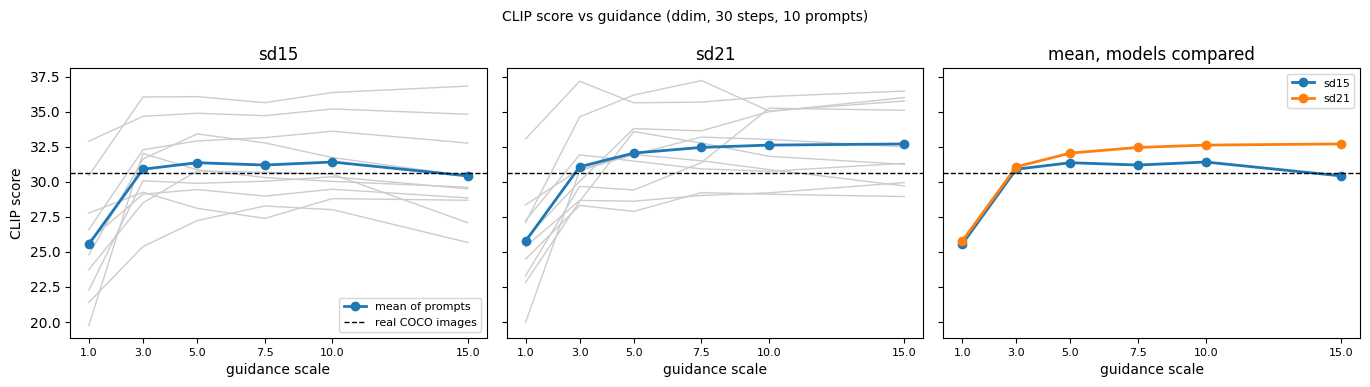

In [12]:
g = df[(df.scheduler == b["scheduler"]) & (df.steps == b["steps"])]
npan = len(MODELS) + (1 if len(MODELS) > 1 else 0)
fig, axes = plt.subplots(1, npan, figsize=(4.6 * npan, 3.9), sharey=True, squeeze=False)
for ax, t in zip(axes[0], MODELS):
    gt = g[g.model_tag == t]
    for iid, grp in gt.groupby("image_id"):
        grp = grp.sort_values("guidance")
        ax.plot(grp["guidance"], grp["clip_score"], color="0.8", lw=1)
    m = gt.groupby("guidance")["clip_score"].mean()
    ax.plot(m.index, m.values, "o-", color="tab:blue", lw=2, label="mean of prompts")
    ax.axhline(REAL_MEAN, ls="--", color="k", lw=1, label="real COCO images")
    ax.set_title(t); ax.set_xlabel("guidance scale"); ax.set_xticks(GUIDANCE_VALUES)
    ax.tick_params(axis="x", labelsize=8)
axes[0][0].set_ylabel("CLIP score"); axes[0][0].legend(fontsize=8)
if len(MODELS) > 1:
    ax = axes[0][-1]
    for t in MODELS:
        m = g[g.model_tag == t].groupby("guidance")["clip_score"].mean()
        ax.plot(m.index, m.values, "o-", lw=2, label=t)
    ax.axhline(REAL_MEAN, ls="--", color="k", lw=1)
    ax.set_title("mean, models compared"); ax.set_xlabel("guidance scale"); ax.set_xticks(GUIDANCE_VALUES)
    ax.tick_params(axis="x", labelsize=8); ax.legend(fontsize=8)
fig.suptitle(f"CLIP score vs guidance ({b['scheduler']}, {b['steps']} steps, 10 prompts)", fontsize=10)
plt.tight_layout()
plt.savefig(M2_RESULTS / "plot_clip_vs_guidance.png", dpi=150, bbox_inches="tight")
plt.show()

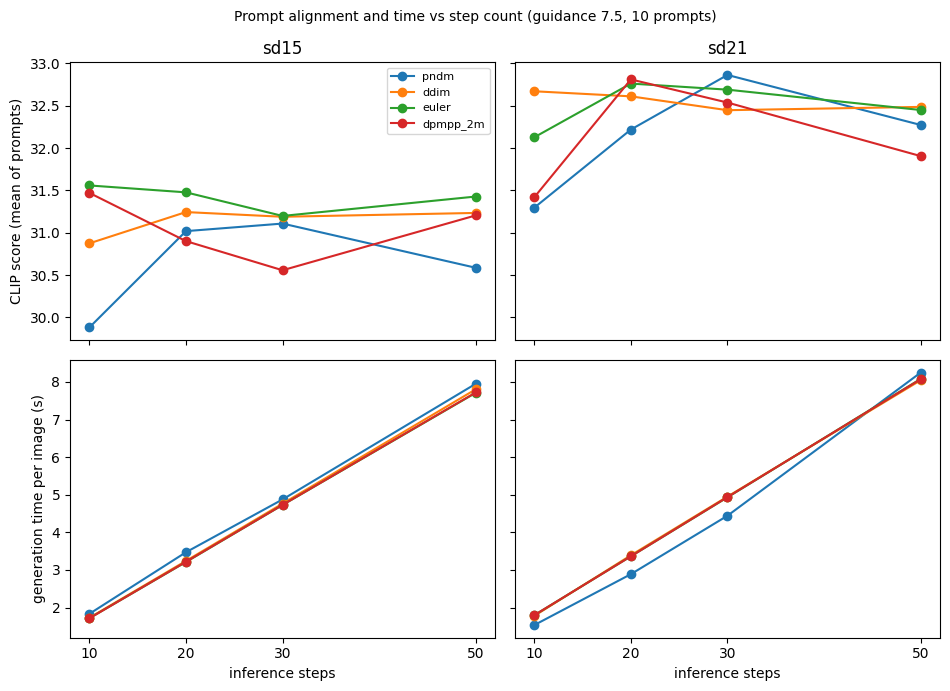

time and memory by guidance value (note: guidance 1.0 skips the empty-prompt pass):
                    gen_time_s  peak_gpu_mem_gb
model_tag guidance                             
sd15      1.0             3.19             2.81
          3.0             4.77             2.81
          5.0             4.77             2.81
          7.5             4.76             2.81
          10.0            4.76             2.81
          15.0            4.76             2.81
sd21      1.0             3.13             3.25
          3.0             4.90             3.25
          5.0             4.94             3.25
          7.5             4.95             3.25
          10.0            4.95             3.25
          15.0            4.90             3.25


In [13]:
COLORS = dict(zip(SCHEDULER_NAMES, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))
s = df[df.guidance == b["guidance"]]
fig, axes = plt.subplots(2, len(MODELS), figsize=(4.8 * len(MODELS), 7), sharex=True, sharey="row", squeeze=False)
for j, t in enumerate(MODELS):
    for sc in SCHEDULER_NAMES:
        grp = s[(s.model_tag == t) & (s.scheduler == sc)].groupby("steps")
        axes[0][j].plot(grp["clip_score"].mean().index, grp["clip_score"].mean().values, "o-", color=COLORS[sc], label=sc)
        axes[1][j].plot(grp["gen_time_s"].mean().index, grp["gen_time_s"].mean().values, "o-", color=COLORS[sc], label=sc)
    axes[0][j].set_title(t); axes[1][j].set_xlabel("inference steps"); axes[1][j].set_xticks(STEP_VALUES)
axes[0][0].set_ylabel("CLIP score (mean of prompts)"); axes[1][0].set_ylabel("generation time per image (s)")
axes[0][0].legend(fontsize=8)
fig.suptitle(f"Prompt alignment and time vs step count (guidance {b['guidance']}, 10 prompts)", fontsize=10)
plt.tight_layout()
plt.savefig(M2_RESULTS / "plot_quality_time_vs_steps.png", dpi=150, bbox_inches="tight")
plt.show()

print("time and memory by guidance value (note: guidance 1.0 skips the empty-prompt pass):")
print(g.groupby(["model_tag", "guidance"])[["gen_time_s", "peak_gpu_mem_gb"]].mean().round(2).to_string())

## 8. Select Submission Samples

This section generates two comparison strips per selected model:

- **Guidance strip:** One prompt evaluated across six guidance values.
- **Scheduler strip:** One prompt evaluated across four schedulers at baseline guidance and inference steps.

Each model contributes 10 images in total. `SAMPLE_MODELS` controls which models are included to stay within the submission limit.

Prompts are ranked by CLIP score variation across each experiment to help identify visually informative examples. Since CLIP scores do not capture every visual detail, the strips should be reviewed before finalizing `STRIP_PROMPT_GUIDANCE` and `STRIP_PROMPT_SCHEDULER`.

Each image is labeled with its experimental setting and CLIP score, and the selected PNGs are copied into the `submission/` directory.

sd15: CLIP score range per prompt (max - min) across the guidance sweep and across schedulers
                  category  guidance_range  scheduler_range
image_id                                                   
3661          simple_scene           12.28             0.49
25181     spatial_relation            8.63             3.00
214200        visible_text            8.08             1.29
5600           two_objects            7.03             2.78
88269         food_closeup            7.02             2.91
1761              counting            6.88             2.92
97924        people_action            6.38             0.71
12670                crowd            3.67             0.60
27972       colour_binding            2.30             0.82
7574      cluttered_indoor            1.87             0.63 



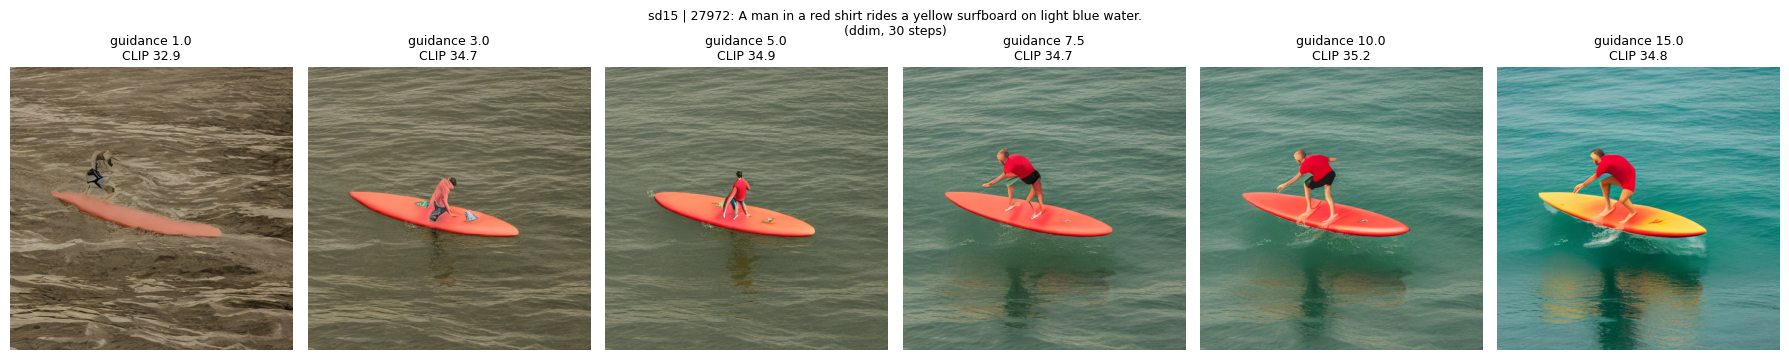

saved strip_guidance_sd15_id27972.png


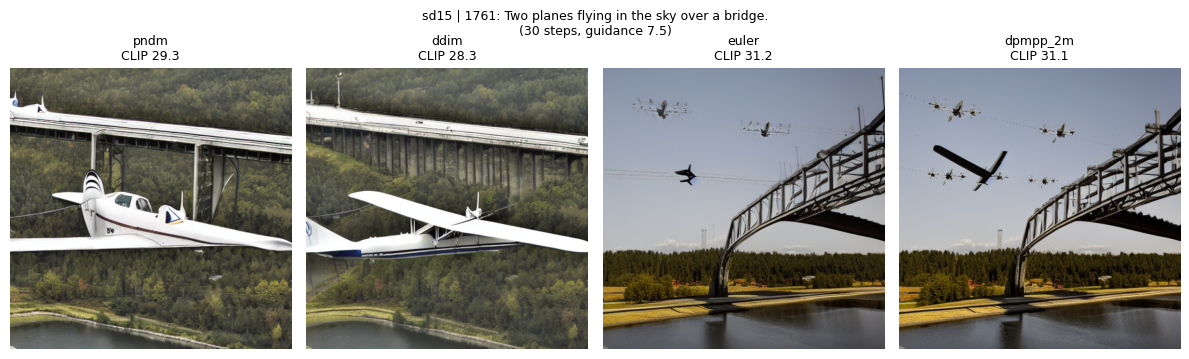

saved strip_scheduler_sd15_id1761.png
10 individual images in submission


In [14]:
for m in SAMPLE_MODELS:
    dm = df[df.model_tag == m]
    g_rng = dm[(dm.scheduler == b["scheduler"]) & (dm.steps == b["steps"])].groupby("image_id")["clip_score"].agg(lambda x: x.max() - x.min())
    s_rng = dm[(dm.guidance == b["guidance"]) & (dm.steps == b["steps"])].groupby("image_id")["clip_score"].agg(lambda x: x.max() - x.min())
    cand = prompts.set_index("image_id")[["category"]].assign(guidance_range=g_rng, scheduler_range=s_rng).round(2)
    print(f"{m}: CLIP score range per prompt (max - min) across the guidance sweep and across schedulers")
    print(cand.sort_values("guidance_range", ascending=False).to_string(), "\n")

def pick(model, iid, sc, st, gd):
    row = df[(df.model_tag == model) & (df.image_id == iid) & (df.scheduler == sc) & (df.steps == st) & (df.guidance == gd)]
    assert len(row) == 1, (model, iid, sc, st, gd, len(row))
    return row.iloc[0]

def strip(model, rows, labels, title, save):
    fig, axes = plt.subplots(1, len(rows), figsize=(3.0 * len(rows), 3.7), squeeze=False)
    for ax, r, lab in zip(axes[0], rows, labels):
        ax.imshow(Image.open(IMG_DIRS[model] / r["filename"])); ax.axis("off")
        ax.set_title(f"{lab}\nCLIP {r['clip_score']:.1f}", fontsize=9)
        shutil.copy2(IMG_DIRS[model] / r["filename"], SUBMIT_DIR / r["filename"])
    fig.suptitle(title, fontsize=9)
    plt.tight_layout()
    plt.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()
    print("saved", save.name)

for m in [x for x in SAMPLE_MODELS if x in MODELS]:
    i = STRIP_PROMPT_GUIDANCE
    rows = [pick(m, i, b["scheduler"], b["steps"], gv) for gv in GUIDANCE_VALUES]
    strip(m, rows, [f"guidance {gv}" for gv in GUIDANCE_VALUES],
          f"{m} | {i}: " + "\n".join(textwrap.wrap(cap_of[i], 110)) + f"\n({b['scheduler']}, {b['steps']} steps)",
          SUBMIT_DIR / f"strip_guidance_{m}_id{i}.png")
    i = STRIP_PROMPT_SCHEDULER
    rows = [pick(m, i, sc, b["steps"], b["guidance"]) for sc in SCHEDULER_NAMES]
    strip(m, rows, SCHEDULER_NAMES,
          f"{m} | {i}: " + "\n".join(textwrap.wrap(cap_of[i], 90)) + f"\n({b['steps']} steps, guidance {b['guidance']})",
          SUBMIT_DIR / f"strip_scheduler_{m}_id{i}.png")
print(len(list(SUBMIT_DIR.glob('*__*.png'))), "individual images in", SUBMIT_DIR.name)